# Explainability Analysis — SHAP

The use of Explainable AI was to show the reasoning behind each model's predictions. For each model, SHAP produced bar plots showing global feature importance, beeswarm plots showing the distribution and direction of each feature's contribution across samples, and waterfall plots for individual predictions.

For the traditional models, **TreeExplainer** was applied to **LightGBM**. For the heterogeneous **ensemble** (XGBoost, Random Forest, and LightGBM), SHAP was computed separately for each component using TreeExplainer, and the resulting values were averaged across the three models. TreeExplainer was chosen because it exploits the internal tree structure to compute exact Shapley values in polynomial time, without requiring sampling or approximation.

For the **RNN** (bidirectional GRU), **GradientExplainer** was used. Since the model is fully differentiable, SHAP values are estimated via integrated gradients through backpropagation. GradientExplainer is well-suited for recurrent architectures because it operates directly on the computational graph, naturally handling the 3D input (samples × channels × timesteps). The resulting SHAP values were aggregated over the time dimension to obtain per-channel signal importance.

For the **DANN**, **DeepExplainer** was applied exclusively to the stress classification branch (feature extractor and stress classifier), excluding the gradient reversal layer, which is only active during training. DeepExplainer is based on DeepLIFT and is efficient for feedforward networks; it is preferred over GradientExplainer for tabular MLPs because it propagates contributions through each layer using reference activations rather than gradients, which is more stable for shallow networks.

For **AutoGluon**, **KernelExplainer** was used because AutoGluon trains a weighted ensemble of heterogeneous models (including gradient boosting, neural networks, and nearest neighbours), whose internal structure is not directly accessible. KernelExplainer is model-agnostic: it treats the predictor as a black box and approximates Shapley values via a weighted linear regression over feature coalitions, making it the only viable choice when the model architecture cannot be assumed.

In [1]:
!pip install shap

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
shap.initjs()

In [3]:
with open('/home/matildxi/Secretária/Documentos/Tese/anxolotl/processed_data/wesad/processed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X_df = data['X']
y    = data['y']

In [4]:
with open('/home/matildxi/Secretária/Documentos/Tese/anxolotl/models_data/lgbm_wrist_final.pkl', 'rb') as f:
    lgbm_data = pickle.load(f)

with open('/home/matildxi/Secretária/Documentos/Tese/anxolotl/models_data/ensemble_wrist_final.pkl', 'rb') as f:
    ensemble_data = pickle.load(f)

print("LightGBM features:", lgbm_data['feature_cols'])
print("Ensemble features:", ensemble_data['feature_cols'])
print("São iguais?", lgbm_data['feature_cols'] == ensemble_data['feature_cols'])

/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1

LightGBM features: ['acc_wrist_mean', 'acc_wrist_std', 'acc_wrist_min', 'acc_wrist_max', 'acc_wrist_p25', 'acc_wrist_p75', 'acc_wrist_skew', 'acc_wrist_kurtosis', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'hr_p25', 'hr_p75', 'hr_skew', 'hr_kurtosis', 'ibi_mean', 'ibi_std', 'ibi_min', 'ibi_max', 'ibi_p25', 'ibi_p75', 'ibi_skew', 'ibi_kurtosis', 'rmssd_mean', 'rmssd_std', 'rmssd_min', 'rmssd_max', 'rmssd_p25', 'rmssd_p75', 'rmssd_skew', 'rmssd_kurtosis', 'sdnn_mean', 'sdnn_std', 'sdnn_min', 'sdnn_max', 'sdnn_p25', 'sdnn_p75', 'sdnn_skew', 'sdnn_kurtosis', 'age', 'gender', 'coffee_last_hour', 'sports', 'smoker', 'ill']
Ensemble features: ['acc_wrist_mean', 'acc_wrist_std', 'acc_wrist_min', 'acc_wrist_max', 'acc_wrist_p25', 'acc_wrist_p75', 'acc_wrist_skew', 'acc_wrist_kurtosis', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'hr_p25', 'hr_p75', 'hr_skew', 'hr_kurtosis', 'ibi_mean', 'ibi_std', 'ibi_min', 'ibi_max', 'ibi_p25', 'ibi_p75', 'ibi_skew', 'ibi_kurtosis', 'rmssd_mean', 'rmssd_std', 'rmss

/tmp/ipykernel_205010/3478983540.py:5: UserWarning: [20:59:07] WARNING: /workspace/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  ensemble_data = pickle.load(f)
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator VotingClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
def prepare_X(model_data, X_df):
    cols    = model_data['feature_cols']
    X_sel   = X_df[cols]
    X_scaled = model_data['imputer'].transform(
                   model_data['scaler'].transform(X_sel))
    return X_scaled, cols

In [6]:
def signal_group_importance(shap_vals, cols):
    groups = {
        'ACC':   [c for c in cols if c.startswith('acc')],
        'EDA':   [c for c in cols if c.startswith('eda')],
        'TEMP':  [c for c in cols if c.startswith('temp')],
        'HR':    [c for c in cols if c.startswith('hr')],
        'IBI':   [c for c in cols if c.startswith('ibi')],
        'RMSSD': [c for c in cols if c.startswith('rmssd')],
        'SDNN':  [c for c in cols if c.startswith('sdnn')],
    }
    importance = {}
    for group, gcols in groups.items():
        idx = [cols.index(c) for c in gcols if c in cols]
        if idx:
            importance[group] = np.abs(shap_vals[:, idx]).mean()
    return importance

In [7]:
def run_shap_analysis(model, X_scaled, cols, model_name, explainer_type='tree'):
    print(f"\n{'='*60}")
    print(f"  SHAP — {model_name}")
    print(f"{'='*60}")

    if explainer_type == 'tree':
        explainer  = shap.TreeExplainer(model)
        shap_vals  = explainer.shap_values(X_scaled)
        expected   = explainer.expected_value
        # para classificação binária pega na classe 1
        if isinstance(shap_vals, list):
            sv = shap_vals[1]
            ev = expected[1]
        else:
            sv = shap_vals
            ev = expected
    else:
        sv = model  # passa shap_vals diretamente quando é ensemble
        ev = 0.0

    X_df_scaled = pd.DataFrame(X_scaled, columns=cols)

    # --- 1. Summary plot (beeswarm) ---
    shap.summary_plot(sv, X_scaled, feature_names=cols,
                    show=False, plot_type='dot')
    plt.title(f'SHAP Summary — {model_name}')
    plt.tight_layout()
    plt.show()

    # --- 2. Bar plot ---
    shap.summary_plot(sv, X_scaled, feature_names=cols,
                  show=False, plot_type='bar')
    plt.title(f'SHAP Bar — {model_name}')
    plt.tight_layout()
    plt.show()

    # --- 3. Por grupo de sinais ---
    gi = signal_group_importance(sv, cols)
    plt.figure(figsize=(8, 5))
    plt.barh(list(gi.keys()), list(gi.values()), color='steelblue')
    plt.title(f'SHAP Importance por Sinal — {model_name}')
    plt.xlabel('Mean |SHAP value|')
    plt.tight_layout()
    plt.show()

    # --- 4. Waterfall — exemplo stress ---
    stress_idx   = np.where(y.values == 1)[0][0]
    baseline_idx = np.where(y.values == 0)[0][0]

    print(f"\nWaterfall — exemplo STRESS (idx {stress_idx})")
    shap.waterfall_plot(shap.Explanation(
        values      = sv[stress_idx],
        base_values = ev,
        data        = X_scaled[stress_idx],
        feature_names = cols
    ))

    print(f"\nWaterfall — exemplo BASELINE (idx {baseline_idx})")
    shap.waterfall_plot(shap.Explanation(
        values      = sv[baseline_idx],
        base_values = ev,
        data        = X_scaled[baseline_idx],
        feature_names = cols
    ))

    # --- 5. Force plot — exemplo stress ---
    print(f"\nForce plot — exemplo STRESS")
    shap.force_plot(ev, sv[stress_idx], X_df_scaled.iloc[stress_idx],
                    matplotlib=True)
    plt.show()

    print(f"\nForce plot — exemplo BASELINE")
    shap.force_plot(ev, sv[baseline_idx], X_df_scaled.iloc[baseline_idx],
                    matplotlib=True)
    plt.show()

    # --- 6. Dependence plot — top 3 features ---
    top3 = np.argsort(np.abs(sv).mean(axis=0))[::-1][:3]
    for i in top3:
        feat = cols[i]
        print(f"\nDependence plot — {feat}")
        shap.dependence_plot(feat, sv, X_df_scaled, show=True)

    # --- 7. Heatmap — só uma amostra de 500 pontos ---
    sample_idx = np.random.choice(len(sv), size=min(500, len(sv)), replace=False)
    sv_sample = sv[sample_idx]
    X_sample = X_scaled[sample_idx]

    shap.plots.heatmap(shap.Explanation(
        values        = sv_sample,
        base_values   = np.full(len(sv_sample), ev),
        data          = X_sample,
        feature_names = cols
    ), show=True)

    return sv, ev


  SHAP — LightGBM


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


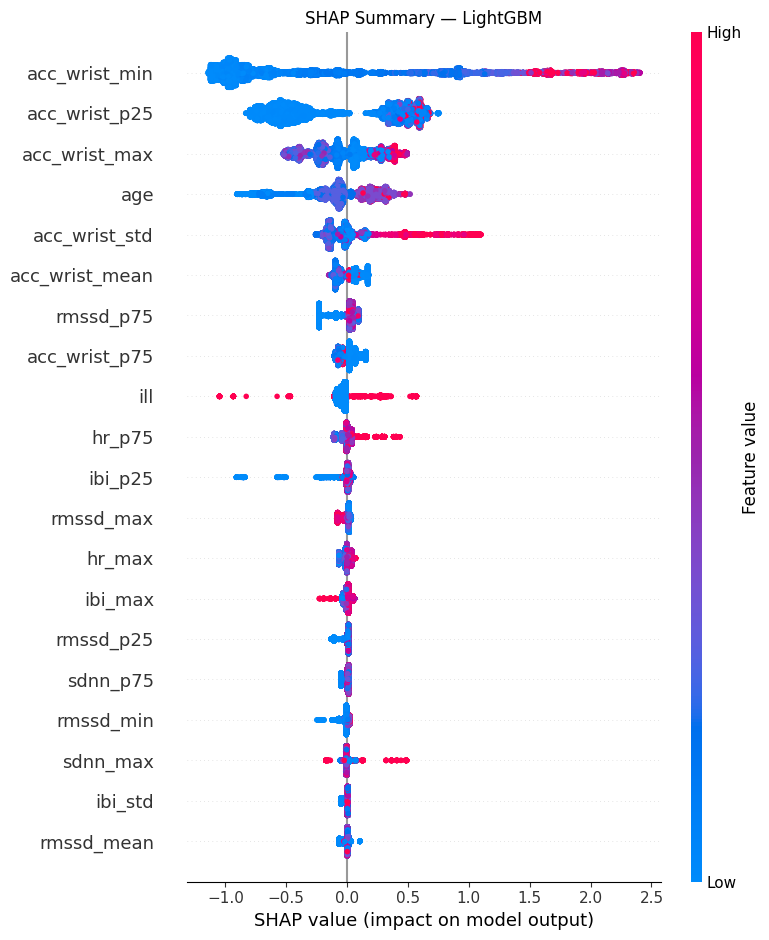

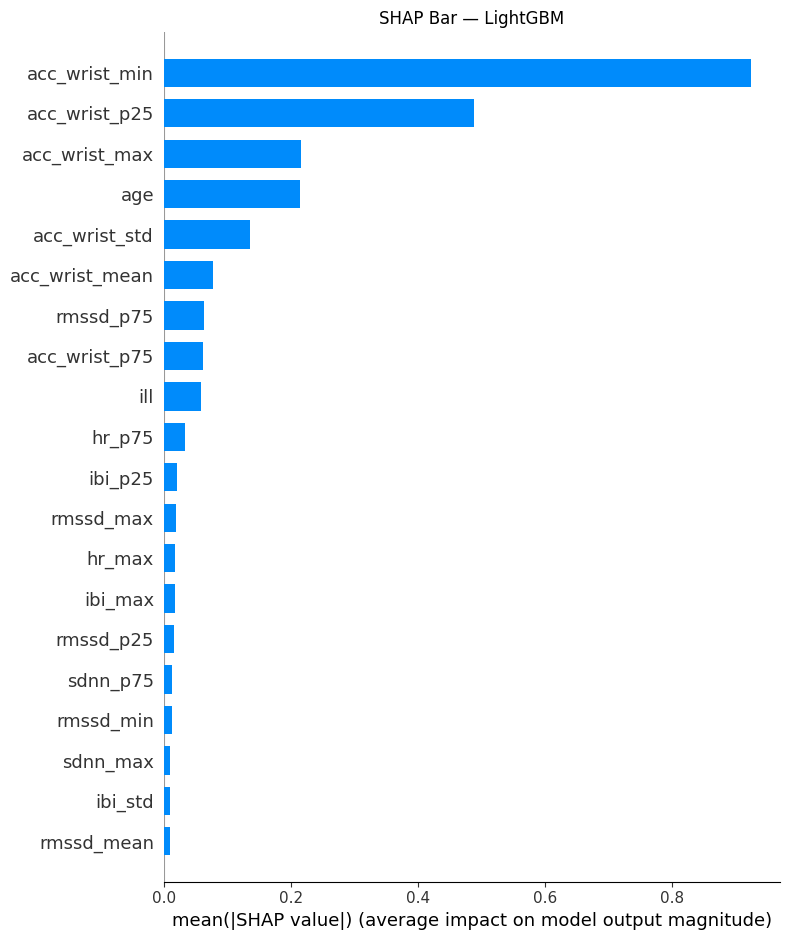

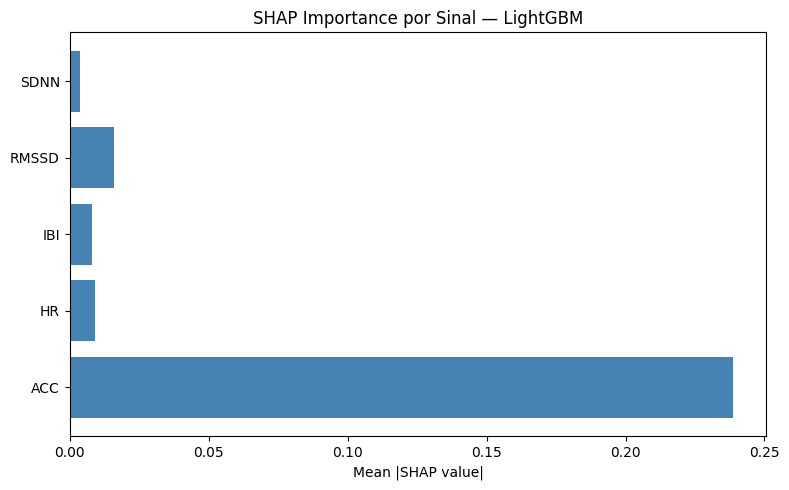


Waterfall — exemplo STRESS (idx 1144)


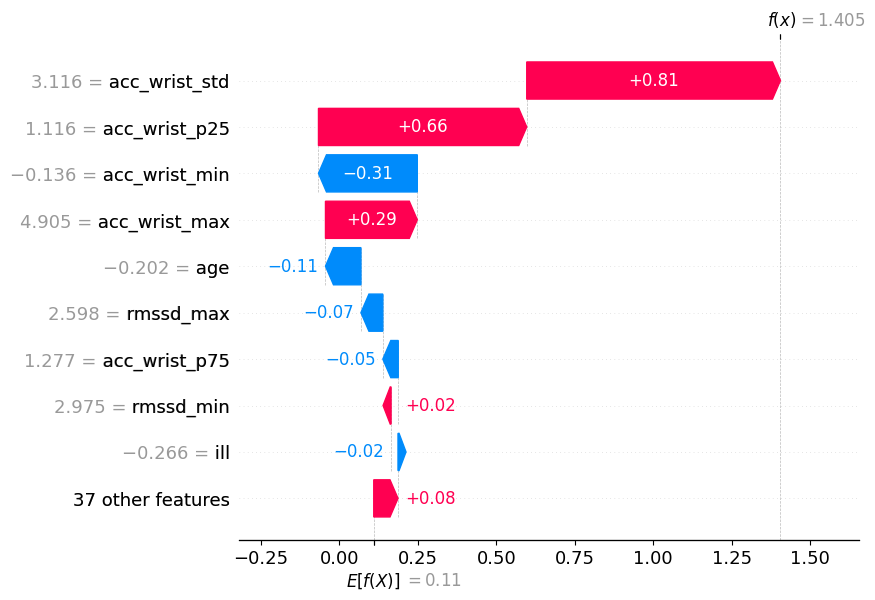


Waterfall — exemplo BASELINE (idx 0)


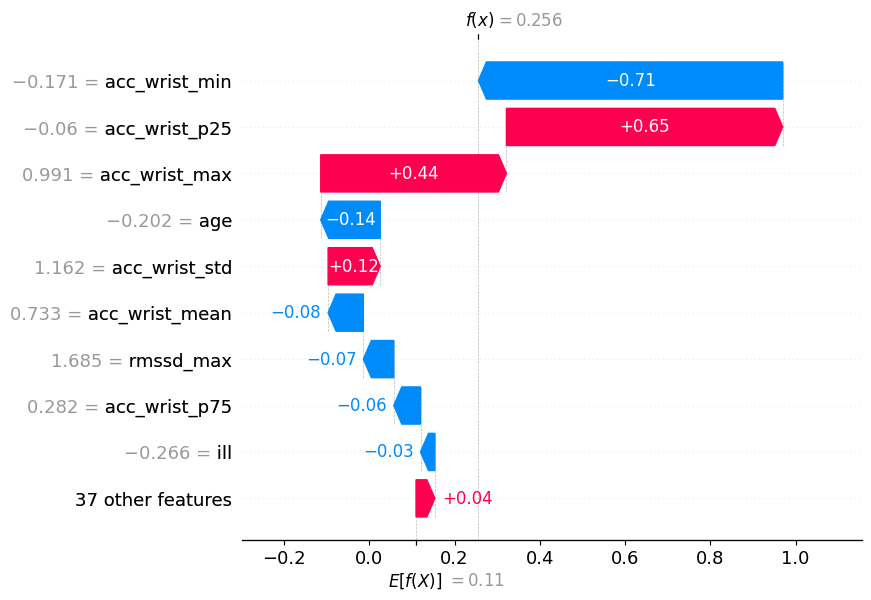


Force plot — exemplo STRESS


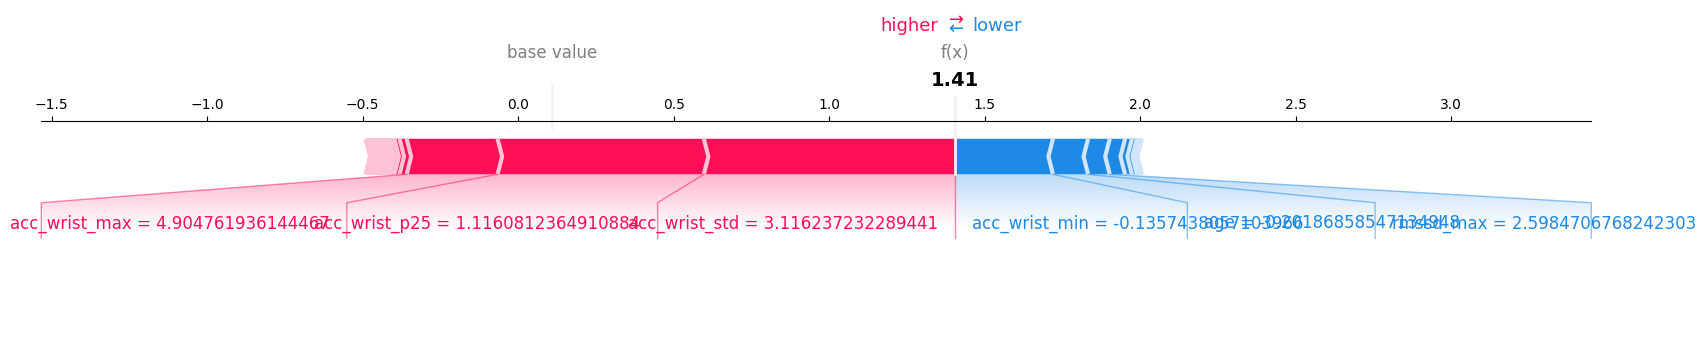


Force plot — exemplo BASELINE


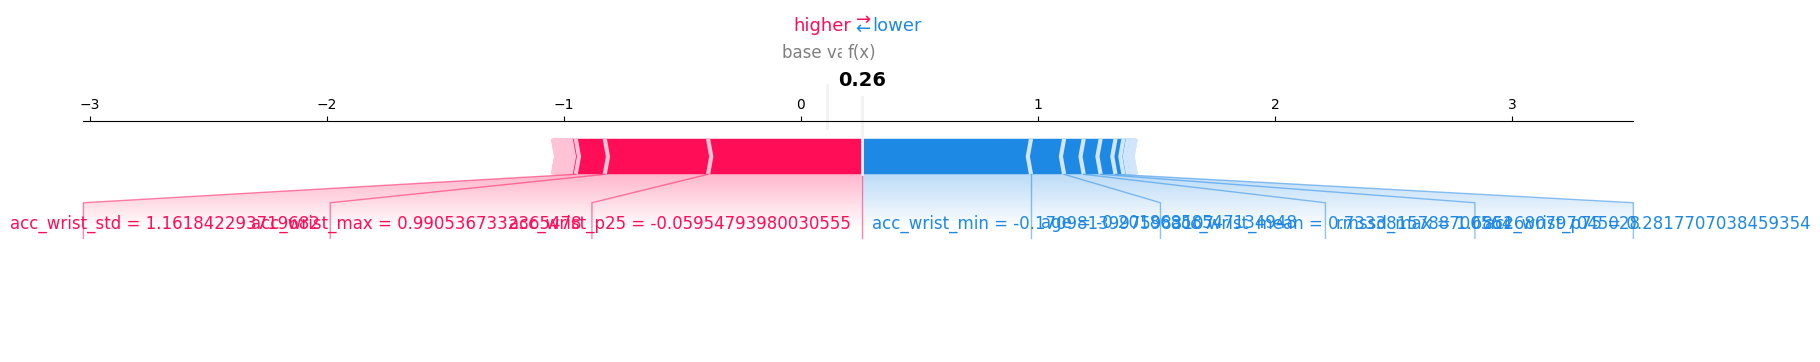


Dependence plot — acc_wrist_min


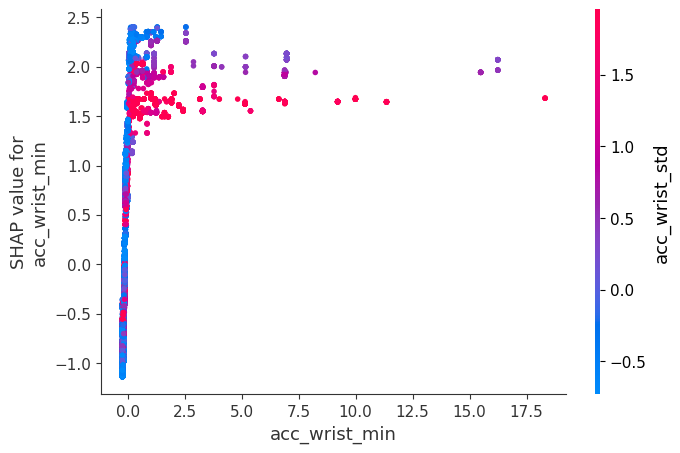


Dependence plot — acc_wrist_p25


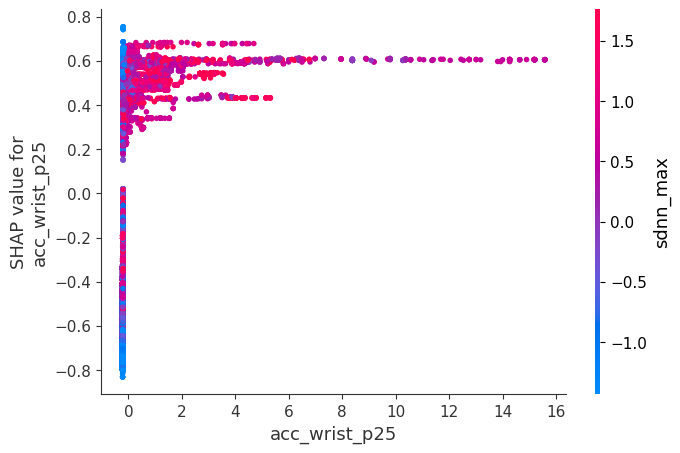


Dependence plot — acc_wrist_max


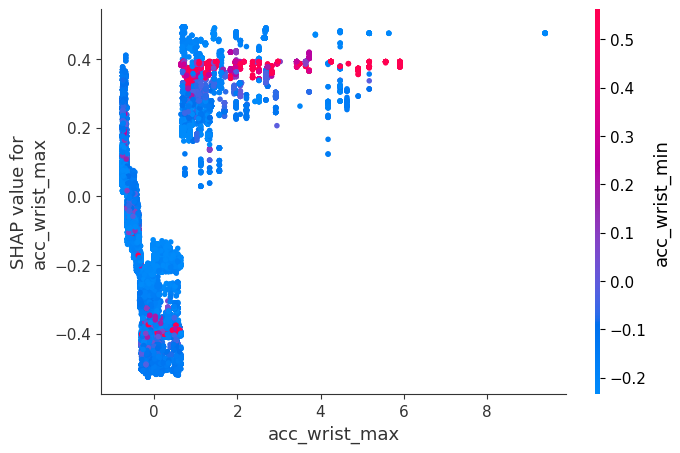

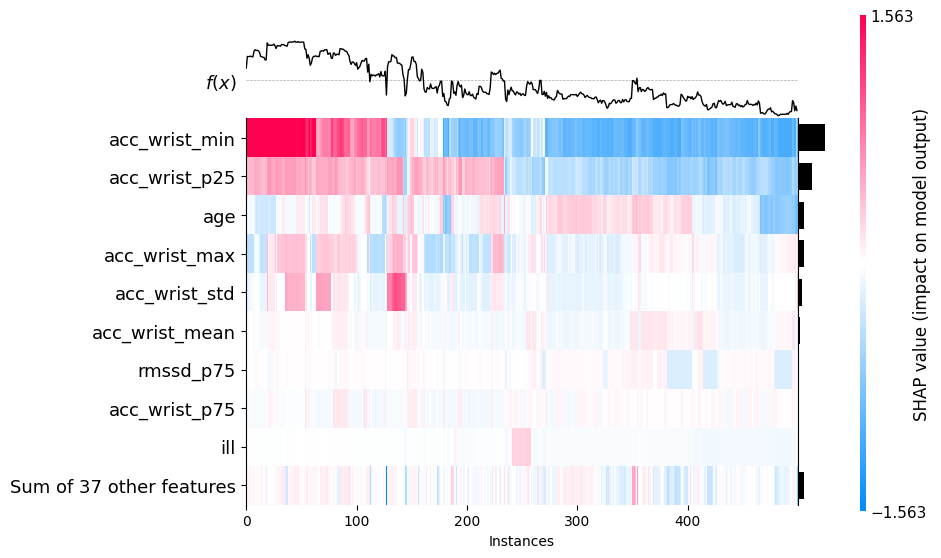

In [8]:
X_lgbm, cols_lgbm = prepare_X(lgbm_data, X_df)
sv_lgbm, ev_lgbm  = run_shap_analysis(
    lgbm_data['model'], X_lgbm, cols_lgbm, 'LightGBM'
)

/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(



  SHAP — Ensemble


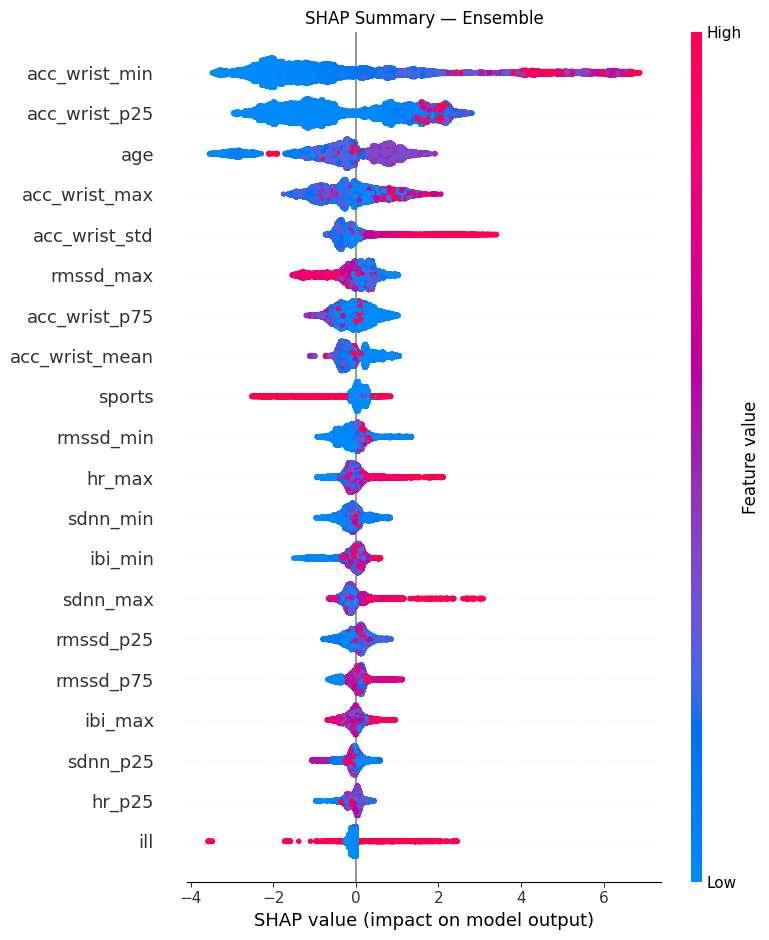

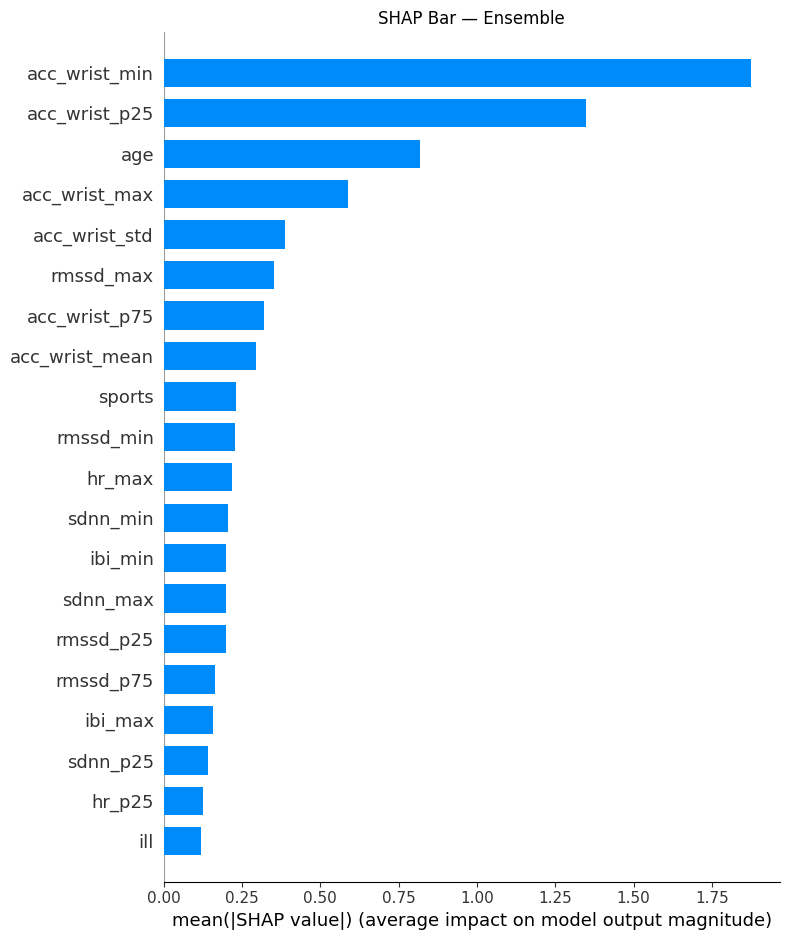

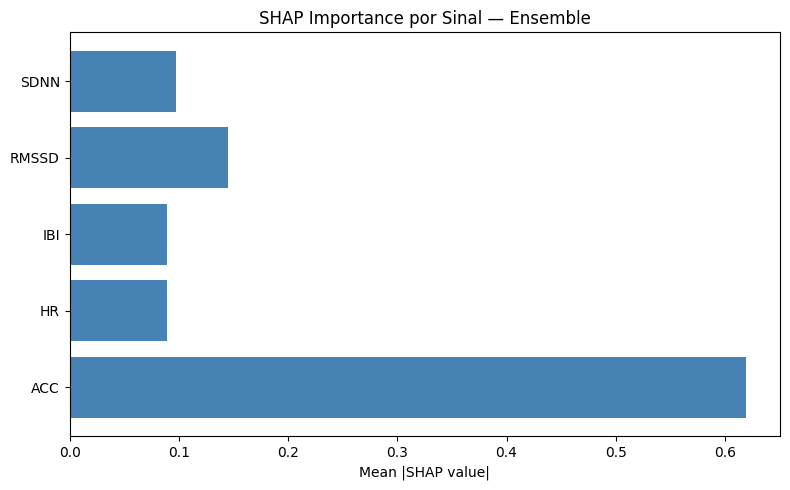


Waterfall — exemplo STRESS (idx 1144)


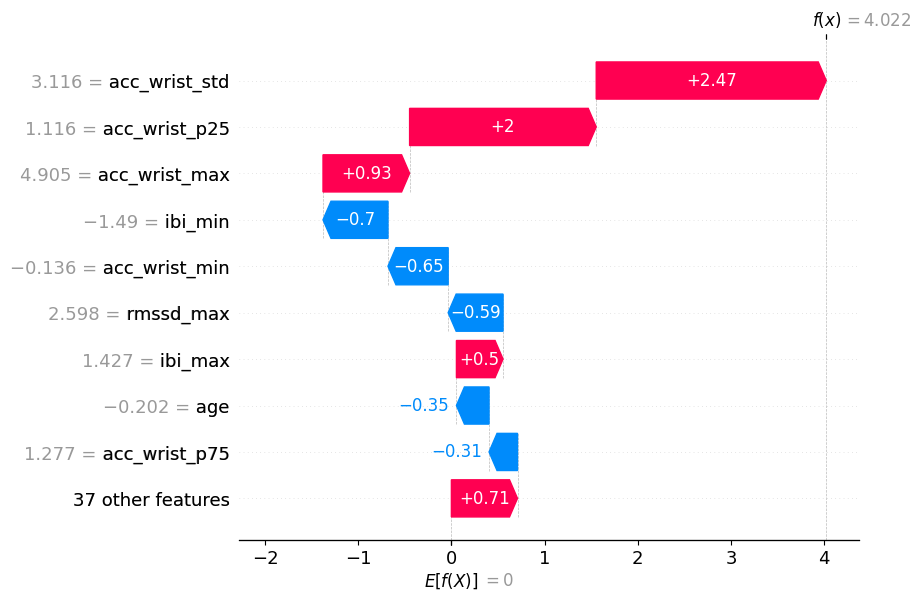


Waterfall — exemplo BASELINE (idx 0)


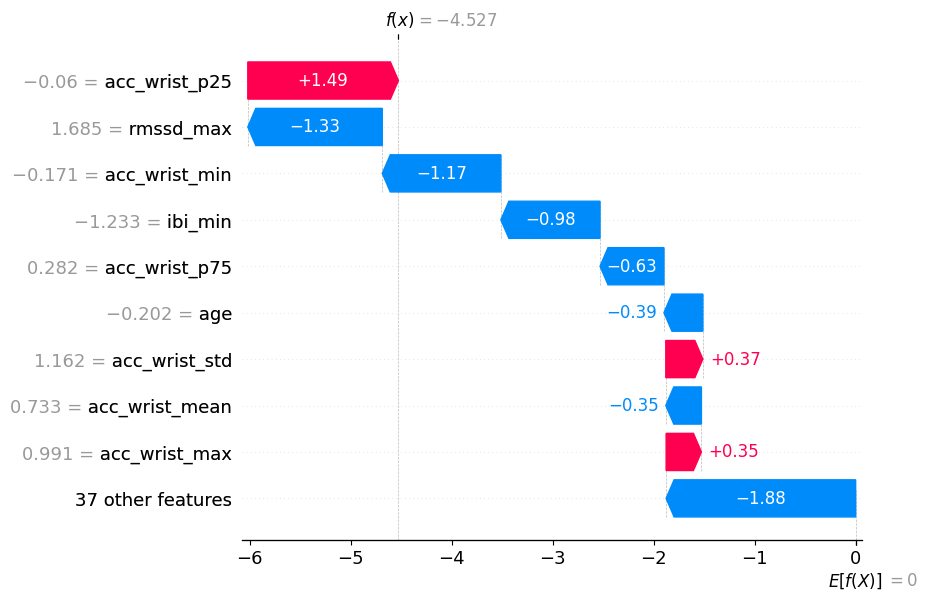


Force plot — exemplo STRESS


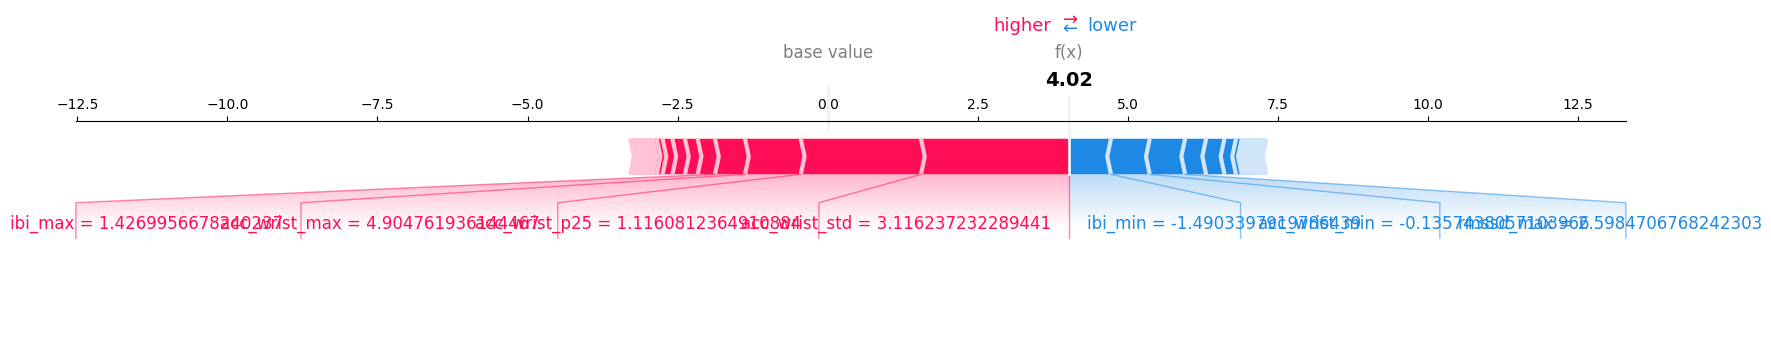


Force plot — exemplo BASELINE


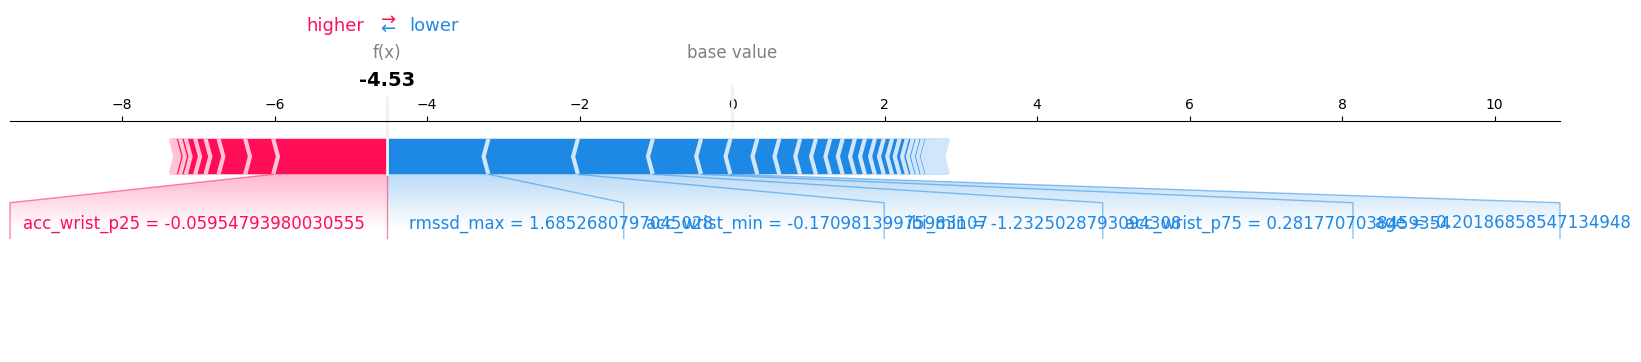


Dependence plot — acc_wrist_min


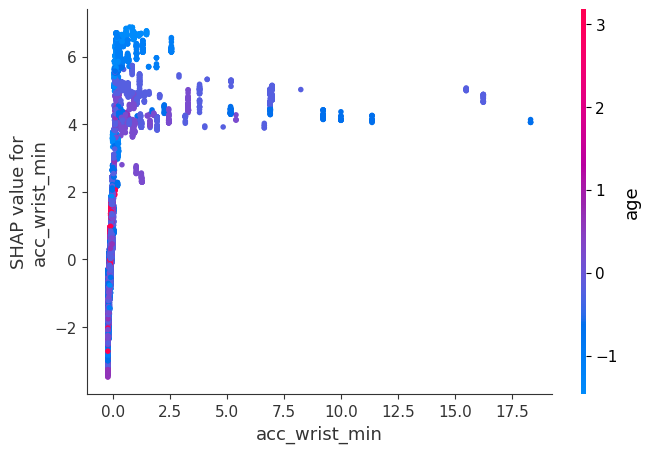


Dependence plot — acc_wrist_p25


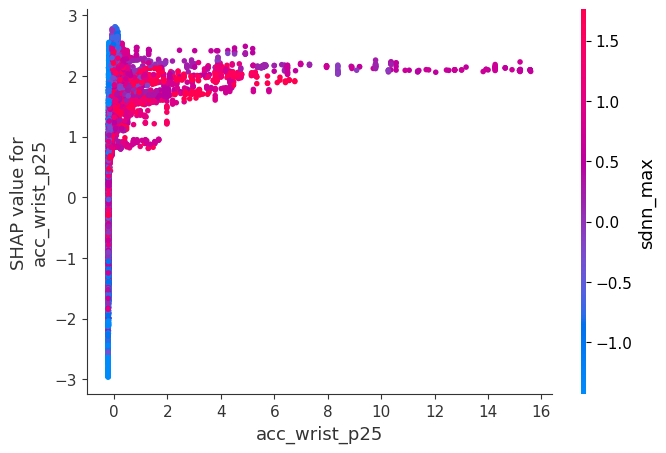


Dependence plot — age


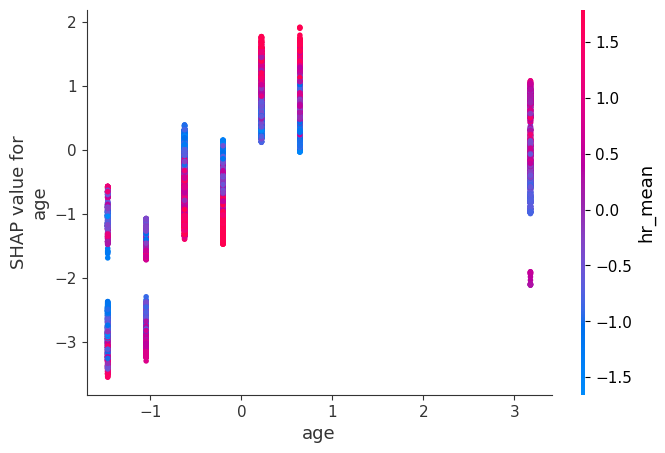

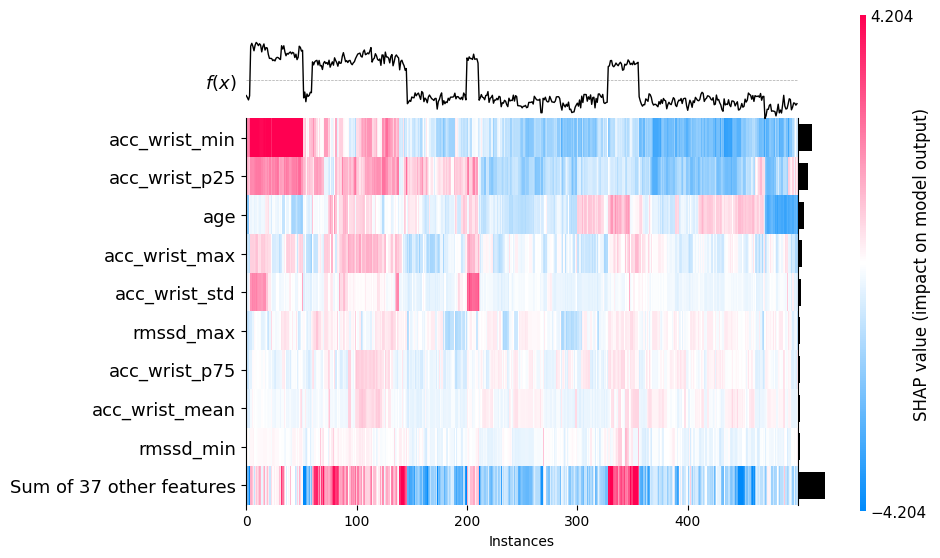

(array([[-0.35284254,  0.36699873, -1.17410571, ..., -0.13136691,
         -0.01609418, -0.04528271],
        [-0.35364435,  0.32115588, -1.17522164, ..., -0.13133849,
         -0.0163325 , -0.04762814],
        [-0.35170079,  0.23442148, -1.15783395, ..., -0.13070043,
         -0.01781607, -0.0465585 ],
        ...,
        [-0.11213035, -0.38995007,  0.31840976, ...,  0.13479499,
          0.00380817, -0.07416545],
        [-0.11193984, -0.43971924,  0.24365977, ...,  0.13488406,
          0.0038044 , -0.07414475],
        [-0.21118514, -0.35261716,  0.23679074, ...,  0.09167442,
          0.00255142, -0.069764  ]], shape=(27543, 46)),
 0.0)

In [9]:
X_ens, cols_ens = prepare_X(ensemble_data, X_df)

explainer_xgb  = shap.TreeExplainer(ensemble_data['model'].named_estimators_['xgb'])
explainer_rf   = shap.TreeExplainer(ensemble_data['model'].named_estimators_['rf'])
explainer_lgbm = shap.TreeExplainer(ensemble_data['model'].named_estimators_['lgbm'])

shap_xgb      = explainer_xgb.shap_values(X_ens)
shap_rf       = explainer_rf.shap_values(X_ens)
shap_ens_lgbm = explainer_lgbm.shap_values(X_ens)

# sem normalização, média direta
def get_sv(s):
    if isinstance(s, list):
        s = s[1]
    if s.ndim == 3:
        s = s[:, :, 1]
    return s

sv_xgb  = get_sv(shap_xgb)
sv_rf   = get_sv(shap_rf)
sv_lgbm = get_sv(shap_ens_lgbm)

sv_ensemble = (sv_xgb + sv_rf + sv_lgbm) / 3

run_shap_analysis(
    sv_ensemble, X_ens, cols_ens, 'Ensemble', explainer_type='custom'
)

In [10]:
import torch
import torch.nn as nn

class RNN1D(nn.Module):
    def __init__(self, input_size=5, hidden_size=128, num_layers=2, num_classes=2):
        super().__init__()
        self.rnn = nn.GRU(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=0.3, bidirectional=True
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = x.permute(0, 2, 1)   # (batch, 60, 5)
        out, _ = self.rnn(x)
        out = out[:, -1, :]
        return self.classifier(out)

device = torch.device('cpu')

rnn_ckpt  = torch.load('/home/matildxi/Secretária/Documentos/Tese/anxolotl/models_data/rnn_wrist_final.pt',
                       map_location=device, weights_only=False)
rnn_model = RNN1D(input_size=5)
rnn_model.load_state_dict(rnn_ckpt['model_state_dict'])
rnn_model.eval()

# Dados sequenciais (sem normalização — modelo treinado em raw data)
with open('/home/matildxi/Secretária/Documentos/Tese/DANN/wesad/processed_data_sequences.pkl', 'rb') as f:
    seq_data = pickle.load(f)

X_seq_all    = seq_data['X_seq']              # (27543, 16, 60)
y_rnn        = seq_data['y_seq']
selected_idx = rnn_ckpt['selected_idx']       # [0, 5, 6, 7, 8]
X_seq        = X_seq_all[:, selected_idx, :].astype(np.float32)  # (27543, 5, 60)

RNN_CH_NAMES = [f'ch_{i:02d}' for i in selected_idx]
print(f"X_seq: {X_seq.shape} | Canais: {RNN_CH_NAMES}")
print(f"Stress: {(y_rnn==1).sum()}  |  Baseline: {(y_rnn==0).sum()}")


X_seq: (27543, 5, 60) | Canais: ['ch_00', 'ch_05', 'ch_06', 'ch_07', 'ch_08']
Stress: 9966  |  Baseline: 17577


A computar SHAP com GradientExplainer...


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/torch/autograd/graph.py:841: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


SHAP shape: (400, 5, 60)


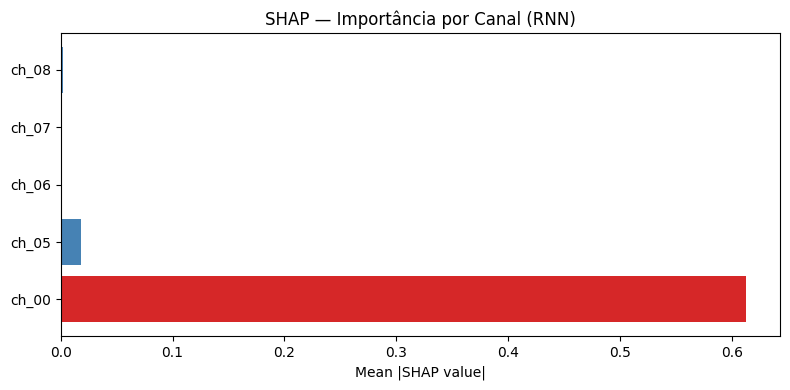

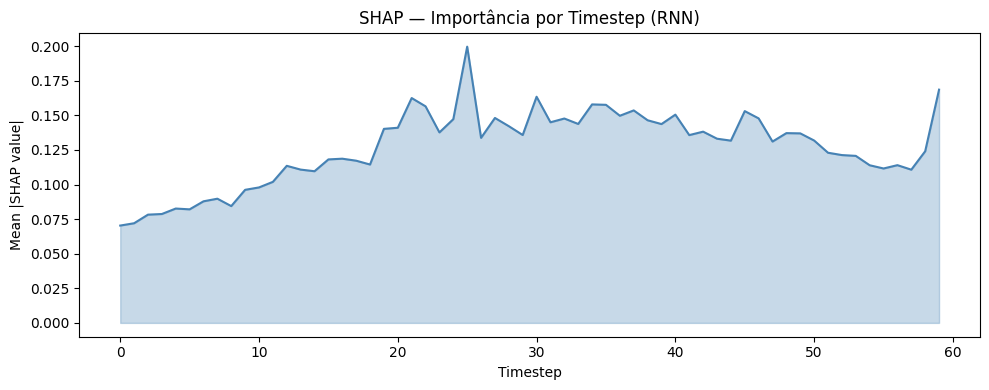

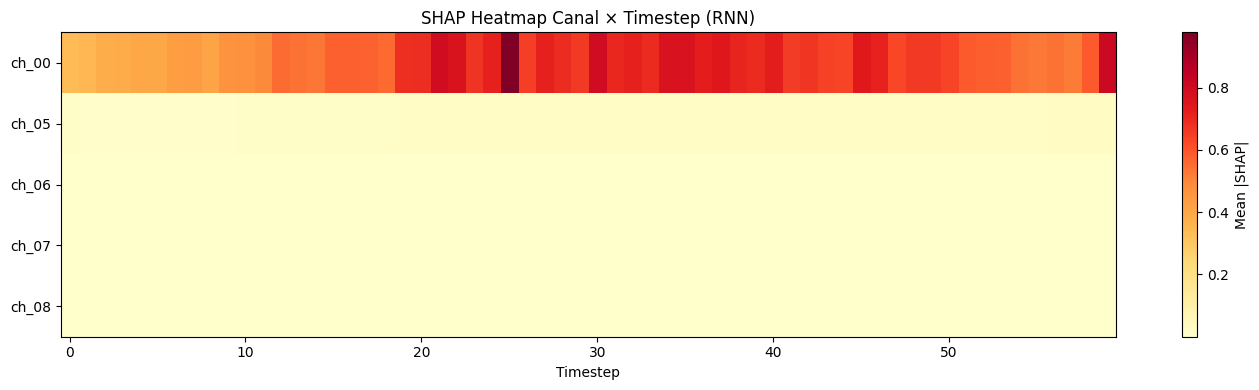

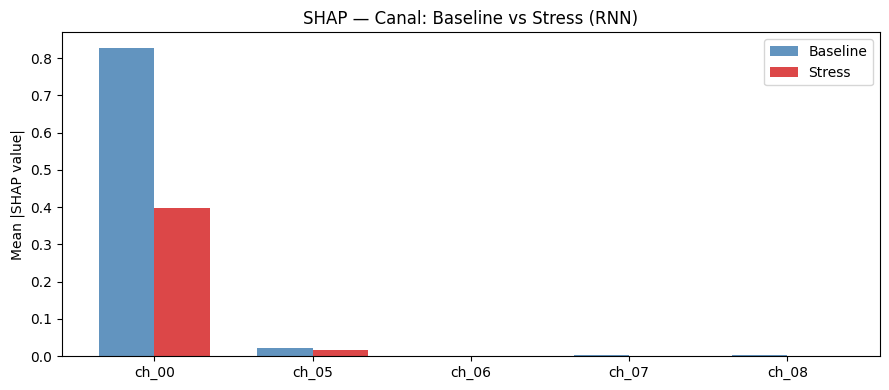


Waterfall — STRESS (RNN, por canal)


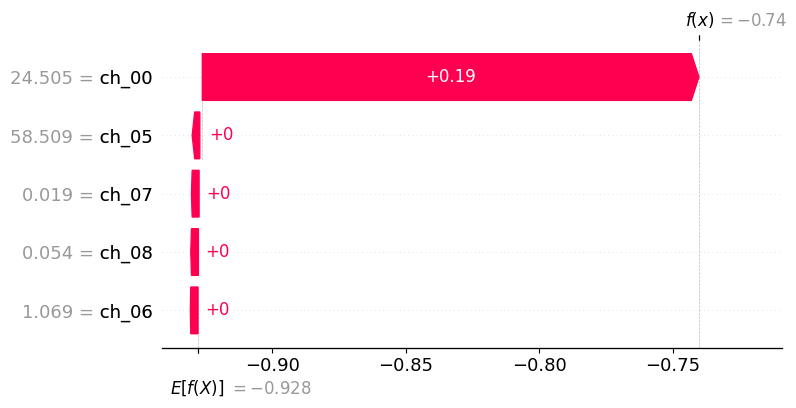


Waterfall — BASELINE (RNN, por canal)


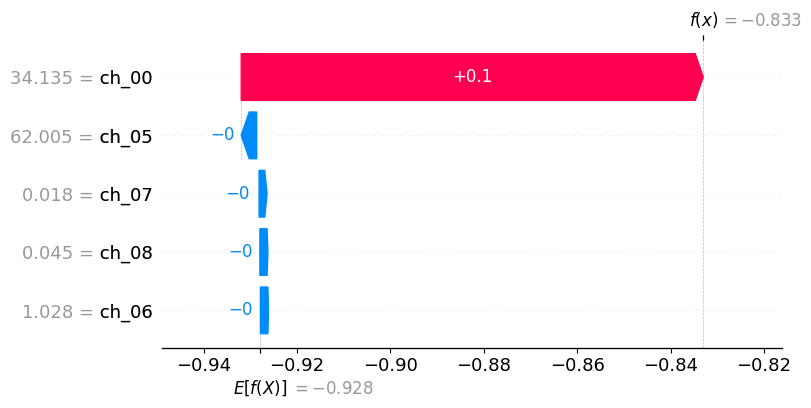

In [11]:
# ── SHAP — RNN (GradientExplainer) ──────────────────────────────
np.random.seed(42)

# Background: 200 amostras balanceadas
bg_0   = np.where(y_rnn == 0)[0][:100]
bg_1   = np.where(y_rnn == 1)[0][:100]
X_bg   = torch.tensor(X_seq[np.concatenate([bg_0, bg_1])])   # (200, 5, 60)

# Test set: 400 amostras (fora do background)
ts_0   = np.where(y_rnn == 0)[0][100:300]
ts_1   = np.where(y_rnn == 1)[0][100:300]
ts_idx = np.concatenate([ts_0, ts_1])
X_ts   = torch.tensor(X_seq[ts_idx])   # (400, 5, 60)
y_ts   = y_rnn[ts_idx]

print("A computar SHAP com GradientExplainer...")
explainer_rnn = shap.GradientExplainer(rnn_model, X_bg)
sv_rnn_all    = explainer_rnn.shap_values(X_ts)   # [cls0, cls1], cada (400,5,60)
# GradientExplainer devolve (n_samples, 5, 60, n_classes)
if isinstance(sv_rnn_all, np.ndarray) and sv_rnn_all.ndim == 4:
    sv_rnn = sv_rnn_all[..., 1]   # (n_samples, 5, 60)
elif isinstance(sv_rnn_all, list):
    sv_rnn = sv_rnn_all[1]
else:
    sv_rnn = sv_rnn_all
print(f"SHAP shape: {sv_rnn.shape}")

with torch.no_grad():
    ev_rnn = rnn_model(X_bg)[:, 1].mean().item()

# ─── 1. Importância por canal ───
ch_imp = np.abs(sv_rnn).mean(axis=(0, 2))   # (5,)
colors = ['#d62728' if i == ch_imp.argmax() else 'steelblue' for i in range(len(RNN_CH_NAMES))]
plt.figure(figsize=(8, 4))
plt.barh(RNN_CH_NAMES, ch_imp, color=colors)
plt.title('SHAP — Importância por Canal (RNN)')
plt.xlabel('Mean |SHAP value|')
plt.tight_layout(); plt.show()

# ─── 2. Importância por timestep ───
t_imp = np.abs(sv_rnn).mean(axis=(0, 1))   # (60,)
plt.figure(figsize=(10, 4))
plt.plot(t_imp, color='steelblue', lw=1.5)
plt.fill_between(range(60), t_imp, alpha=0.3, color='steelblue')
plt.title('SHAP — Importância por Timestep (RNN)')
plt.xlabel('Timestep'); plt.ylabel('Mean |SHAP value|')
plt.tight_layout(); plt.show()

# ─── 3. Heatmap canal × timestep ───
heat = np.abs(sv_rnn).mean(axis=0)   # (5, 60)
plt.figure(figsize=(14, 4))
plt.imshow(heat, aspect='auto', cmap='YlOrRd', interpolation='nearest')
plt.colorbar(label='Mean |SHAP|')
plt.yticks(range(len(RNN_CH_NAMES)), RNN_CH_NAMES)
plt.xlabel('Timestep')
plt.title('SHAP Heatmap Canal × Timestep (RNN)')
plt.tight_layout(); plt.show()

# ─── 4. Baseline vs Stress por canal ───
ch_bl  = np.abs(sv_rnn[y_ts == 0]).mean(axis=(0, 2))
ch_str = np.abs(sv_rnn[y_ts == 1]).mean(axis=(0, 2))
x_ax   = np.arange(len(RNN_CH_NAMES)); w = 0.35
plt.figure(figsize=(9, 4))
plt.bar(x_ax - w/2, ch_bl,  w, label='Baseline', color='steelblue', alpha=0.85)
plt.bar(x_ax + w/2, ch_str, w, label='Stress',   color='#d62728',   alpha=0.85)
plt.xticks(x_ax, RNN_CH_NAMES); plt.ylabel('Mean |SHAP value|')
plt.title('SHAP — Canal: Baseline vs Stress (RNN)')
plt.legend(); plt.tight_layout(); plt.show()

# ─── 5. Waterfall (valores SHAP agregados sobre timesteps por canal) ───
sv_ch = sv_rnn.mean(axis=2)          # (400, 5) — média temporal
X_ch  = X_ts.numpy().mean(axis=2)    # (400, 5)

for label, idx in [('STRESS',   np.where(y_ts == 1)[0][0]),
                   ('BASELINE', np.where(y_ts == 0)[0][0])]:
    print(f"\nWaterfall — {label} (RNN, por canal)")
    shap.waterfall_plot(shap.Explanation(
        values        = sv_ch[idx],
        base_values   = ev_rnn,
        data          = X_ch[idx],
        feature_names = RNN_CH_NAMES
    ))


In [12]:
from autogluon.tabular import TabularPredictor

ag_path = '/home/matildxi/Secretária/Documentos/Tese/anxolotl/models_data/autogluon_wrist_final'
predictor = TabularPredictor.load(ag_path)

# Carregar df completo (inclui eda_wrist e temp_wrist)
with open('/home/matildxi/Secretária/Documentos/Tese/anxolotl/processed_data/wesad/processed_data.pkl', 'rb') as f:
    wesad_full = pickle.load(f)

df_full      = wesad_full['df']
y_ag         = wesad_full['y']

wrist_cols_ag = [c for c in df_full.columns if c not in ['subject', 'label'] and
                 c.startswith(('acc_wrist', 'eda_wrist', 'temp_wrist',
                                'hr_', 'ibi_', 'rmssd_', 'sdnn_'))]
X_ag = df_full[wrist_cols_ag].values
print(f"Features AutoGluon: {len(wrist_cols_ag)}")

print("\nLeaderboard (top 5):")
lb = predictor.leaderboard(silent=True)
print(lb[['model', 'score_val']].head(5).to_string(index=False))


Features AutoGluon: 56

Leaderboard (top 5):
                  model  score_val
      LightGBMXT_BAG_L1        1.0
RandomForestEntr_BAG_L1        1.0
RandomForestGini_BAG_L1        1.0
  ExtraTreesEntr_BAG_L1        1.0
    WeightedEnsemble_L3        1.0


Expected value: 0.4501
A computar SHAP KernelExplainer (pode demorar alguns minutos)...


SHAP shape: (150, 56)


/tmp/ipykernel_205010/4233501101.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_ag, X_sh_ag, feature_names=wrist_cols_ag, show=False)


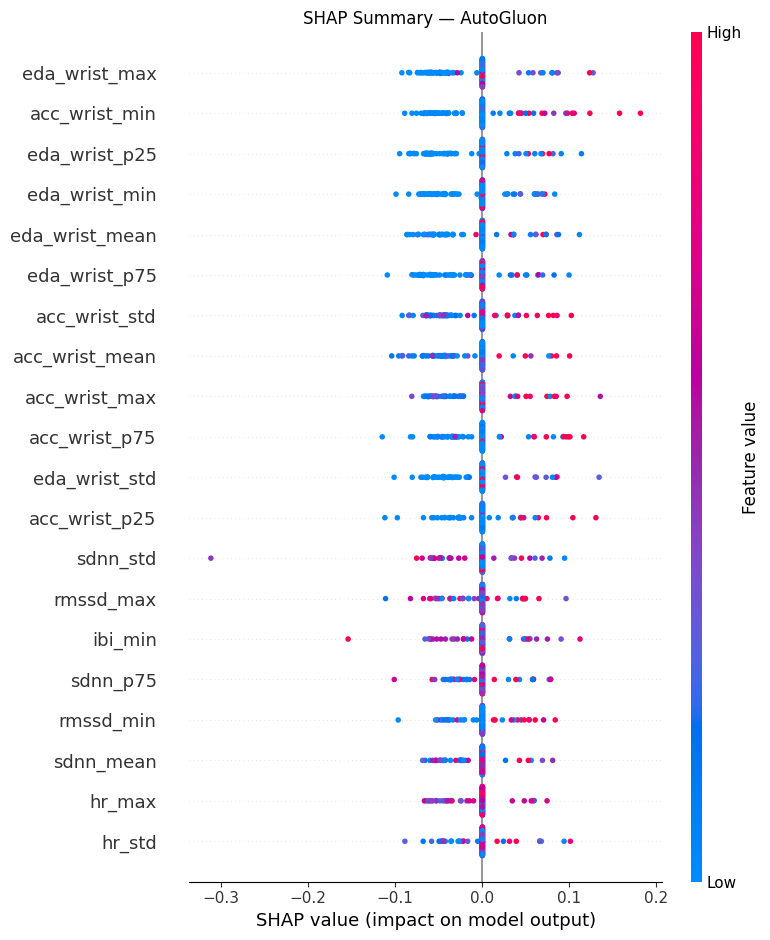

/tmp/ipykernel_205010/4233501101.py:30: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_ag, X_sh_ag, feature_names=wrist_cols_ag,


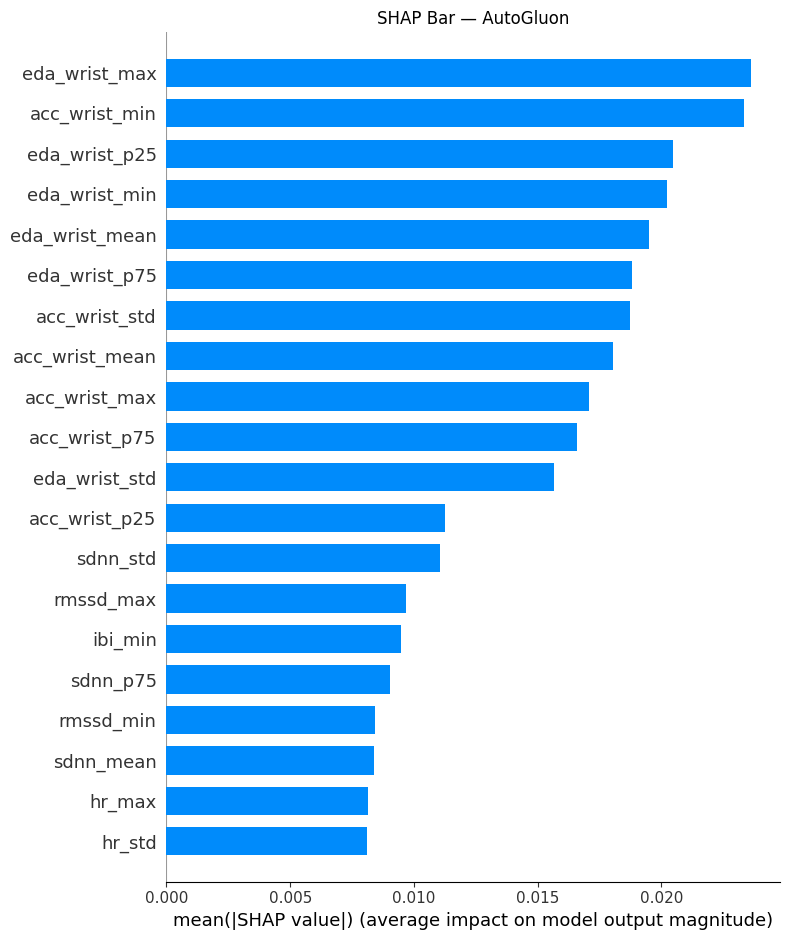

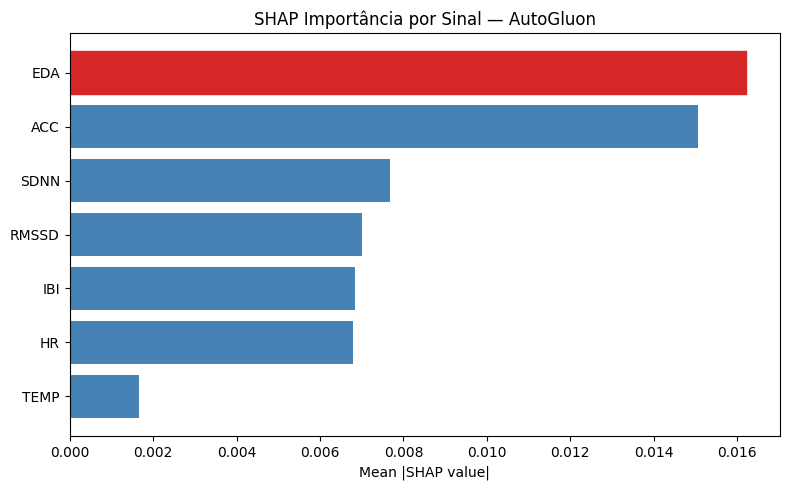


Waterfall — STRESS (AutoGluon)


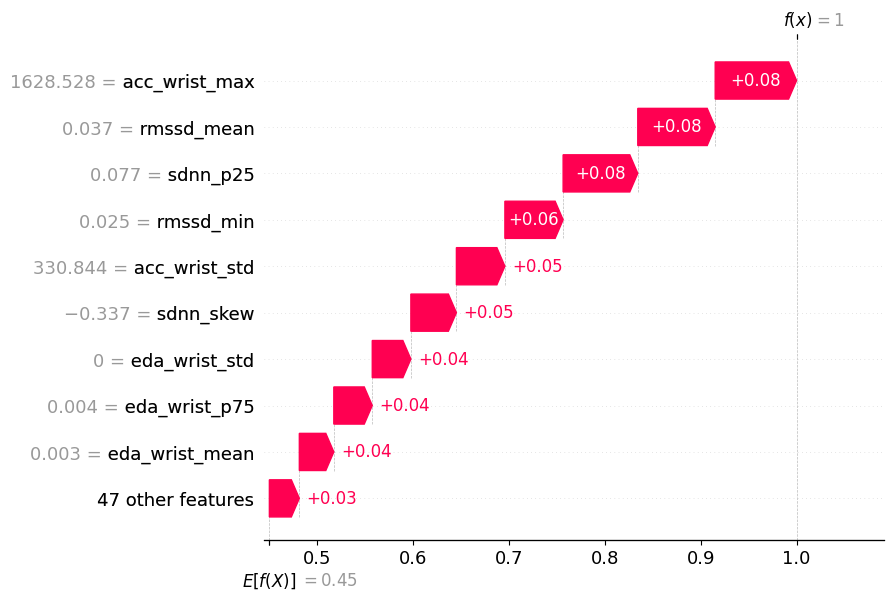


Waterfall — BASELINE (AutoGluon)


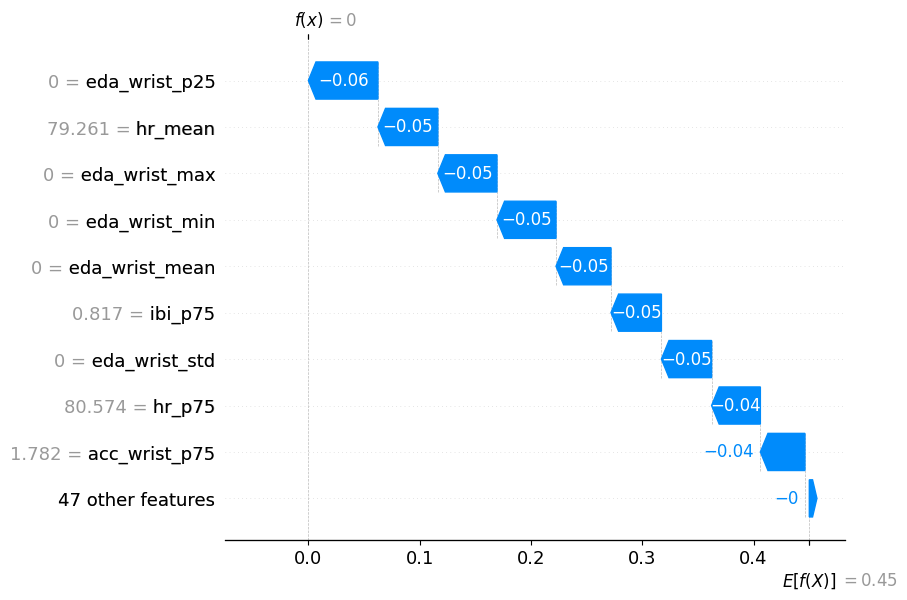

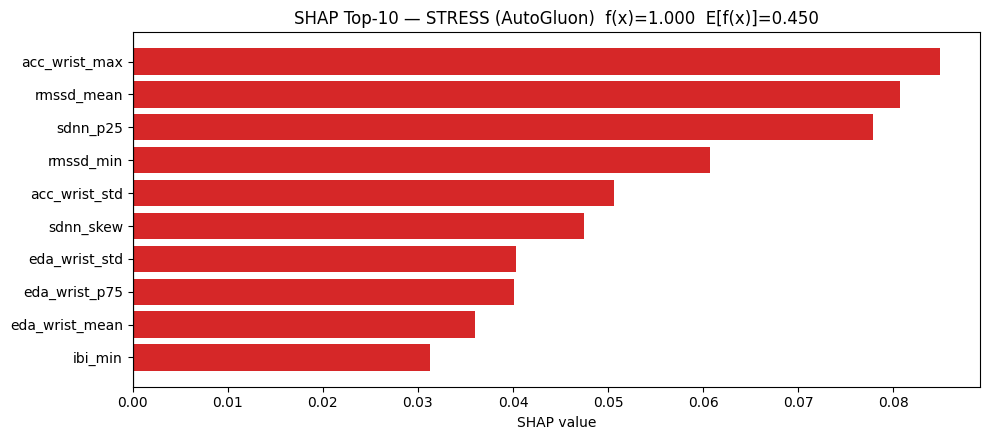

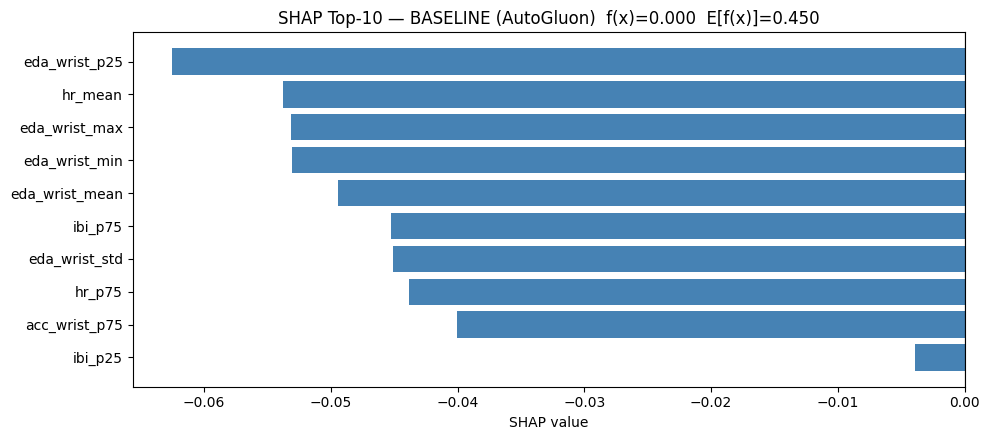

In [13]:
# ── SHAP — AutoGluon (KernelExplainer) ──────────────────────────
np.random.seed(42)

bg_size = 40
sh_size = 150

idx_all   = np.random.choice(len(X_ag), bg_size + sh_size, replace=False)
X_bg_ag   = X_ag[idx_all[:bg_size]]
X_sh_ag   = X_ag[idx_all[bg_size:]]
y_sh_ag   = y_ag[idx_all[bg_size:]]

def ag_proba(X_np):
    df_tmp = pd.DataFrame(X_np, columns=wrist_cols_ag)
    return predictor.predict_proba(df_tmp).iloc[:, 1].values

ev_ag = float(ag_proba(X_bg_ag).mean())
print(f"Expected value: {ev_ag:.4f}")

print("A computar SHAP KernelExplainer (pode demorar alguns minutos)...")
explainer_ag = shap.KernelExplainer(ag_proba, X_bg_ag, silent=True)
sv_ag        = explainer_ag.shap_values(X_sh_ag, nsamples=100, silent=True)
print(f"SHAP shape: {np.array(sv_ag).shape}")

# ─── 1. Summary beeswarm ───
shap.summary_plot(sv_ag, X_sh_ag, feature_names=wrist_cols_ag, show=False)
plt.title('SHAP Summary — AutoGluon')
plt.tight_layout(); plt.show()

# ─── 2. Bar plot ───
shap.summary_plot(sv_ag, X_sh_ag, feature_names=wrist_cols_ag,
                  plot_type='bar', show=False)
plt.title('SHAP Bar — AutoGluon')
plt.tight_layout(); plt.show()

# ─── 3. Por grupo de sinais (ordenado por importância) ───
gi_ag = signal_group_importance(sv_ag, wrist_cols_ag)
gi_ag_sorted = dict(sorted(gi_ag.items(), key=lambda x: x[1]))
plt.figure(figsize=(8, 5))
bars = plt.barh(list(gi_ag_sorted.keys()), list(gi_ag_sorted.values()), color='steelblue')
bars[-1].set_color('#d62728')  # destaca o mais importante
plt.title('SHAP Importância por Sinal — AutoGluon')
plt.xlabel('Mean |SHAP value|')
plt.tight_layout(); plt.show()

# ─── 4. Waterfall ───
X_df_sh_ag = pd.DataFrame(X_sh_ag, columns=wrist_cols_ag)
for label, idx in [('STRESS',   np.where(y_sh_ag == 1)[0][0]),
                   ('BASELINE', np.where(y_sh_ag == 0)[0][0])]:
    print(f"\nWaterfall — {label} (AutoGluon)")
    shap.waterfall_plot(shap.Explanation(
        values        = sv_ag[idx],
        base_values   = ev_ag,
        data          = X_sh_ag[idx],
        feature_names = wrist_cols_ag
    ))

# ─── 5. Top-N individual explanation (filtra contribuições negligenciáveis) ───
for label, idx in [('STRESS',   np.where(y_sh_ag == 1)[0][0]),
                   ('BASELINE', np.where(y_sh_ag == 0)[0][0])]:
    sv_i      = sv_ag[idx]
    top_idx   = np.argsort(np.abs(sv_i))[::-1][:15]
    threshold = np.abs(sv_i[top_idx]).max() * 0.05   # ≥5% do máximo
    mask      = np.abs(sv_i[top_idx]) >= threshold
    top_idx   = top_idx[mask]
    sv_top    = sv_i[top_idx]
    feat_top  = np.array(wrist_cols_ag)[top_idx]
    colors    = ['#d62728' if v > 0 else 'steelblue' for v in sv_top]
    fx        = ev_ag + sv_ag[idx].sum()
    n_shown   = len(feat_top)
    plt.figure(figsize=(10, max(4, n_shown * 0.45)))
    plt.barh(feat_top[::-1], sv_top[::-1], color=colors[::-1])
    plt.axvline(0, color='black', linewidth=0.8)
    plt.title(f'SHAP Top-{n_shown} — {label} (AutoGluon)  f(x)={fx:.3f}  E[f(x)]={ev_ag:.3f}')
    plt.xlabel('SHAP value')
    plt.tight_layout(); plt.show()


In [14]:
from torch.autograd import Function

class GRL(Function):
    @staticmethod
    def forward(ctx, x, lam): ctx.lam = lam; return x
    @staticmethod
    def backward(ctx, grad):  return grad.neg() * ctx.lam, None

class FeatureExtractor(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(),
            nn.Linear(128, 64),         nn.ReLU()
        )
    def forward(self, x): return self.rede(x)

class StressClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 2)
        )
    def forward(self, x): return self.rede(x)

class DomainDiscriminator(nn.Module):
    def __init__(self, n_subjects):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, n_subjects)
        )
    def forward(self, x, lam): return self.rede(GRL.apply(x, lam))

class DANNClassifier(nn.Module):
    """Apenas extractor + stress_cls (sem GRL) para SHAP."""
    def __init__(self, n_features):
        super().__init__()
        self.extractor  = FeatureExtractor(n_features)
        self.stress_cls = StressClassifier()
    def forward(self, x):
        return self.stress_cls(self.extractor(x))

# Carregar checkpoint
dann_ckpt = torch.load('/home/matildxi/Secretária/Documentos/Tese/anxolotl/models_data/dann_wrist_final.pt',
                       map_location='cpu', weights_only=False)

n_feat_dann = dann_ckpt['n_features']   # 20
dann_cls    = DANNClassifier(n_feat_dann)
sub_state   = {k: v for k, v in dann_ckpt['model_state_dict'].items()
               if k.startswith('extractor.') or k.startswith('stress_cls.')}
dann_cls.load_state_dict(sub_state)
dann_cls.eval()

dann_feat_cols = dann_ckpt['feature_cols']
dann_top_k     = dann_ckpt['top_k_idx']
dann_scaler    = dann_ckpt['scaler']
dann_imputer   = dann_ckpt['imputer']
dann_sel_cols  = [dann_feat_cols[i] for i in dann_top_k]

print(f"Features DANN selecionadas ({len(dann_sel_cols)}):")
for c in dann_sel_cols: print(f"  {c}")

# Preparar X: imputer → scaler → top_k (mesma pipeline do treino)
X_dann_scaled = dann_imputer.transform(dann_scaler.transform(X_df[dann_feat_cols]))
X_dann_sel    = X_dann_scaled[:, dann_top_k].astype(np.float32)   # (27543, 20)
print(f"\nX_dann_sel: {X_dann_sel.shape}")


Features DANN selecionadas (20):
  acc_wrist_min
  acc_wrist_max
  sdnn_min
  rmssd_min
  acc_wrist_p25
  rmssd_max
  acc_wrist_p75
  sdnn_max
  rmssd_p25
  sdnn_p25
  rmssd_p75
  sdnn_p75
  hr_max
  ibi_min
  hr_min
  ibi_max
  acc_wrist_std
  ibi_p75
  hr_p25
  ibi_p25

X_dann_sel: (27543, 20)


/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/matildxi/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


A computar SHAP com DeepExplainer...


SHAP shape: (400, 20)  |  Expected value: 36.0786


/tmp/ipykernel_205010/2509072091.py:35: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_dann, X_ts_np, feature_names=dann_sel_cols, show=False)


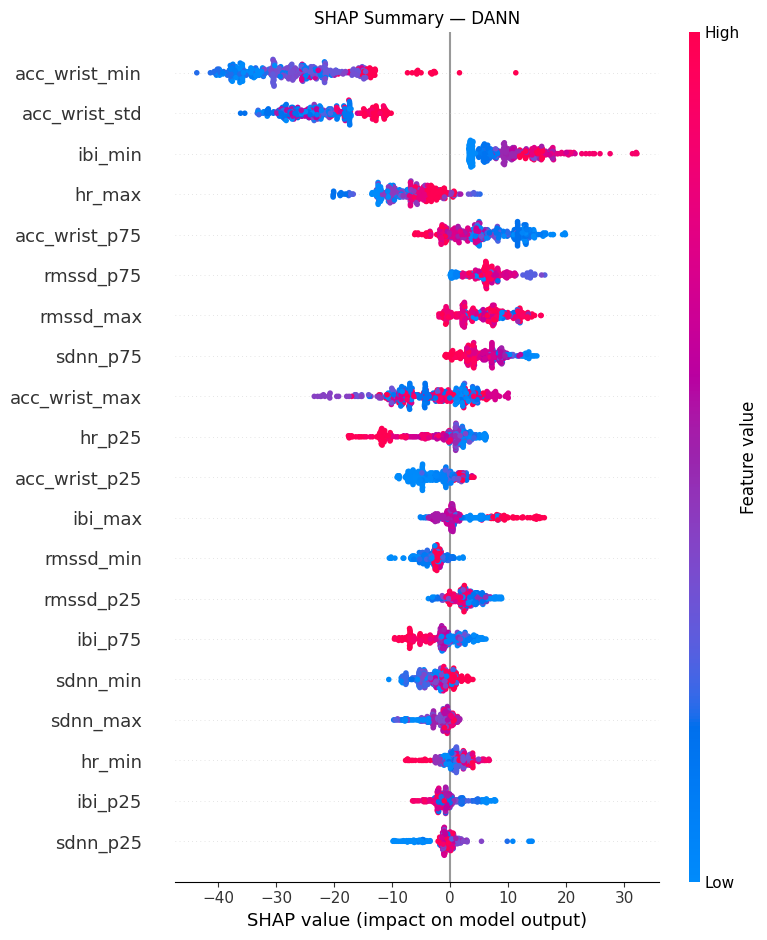

/tmp/ipykernel_205010/2509072091.py:40: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_dann, X_ts_np, feature_names=dann_sel_cols,


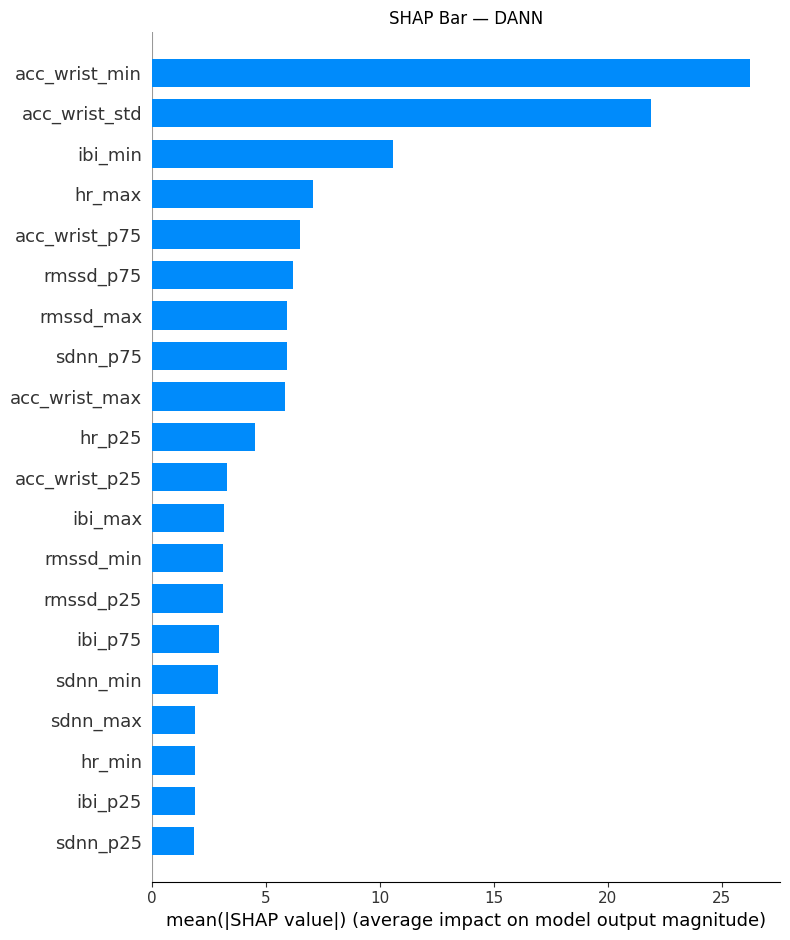

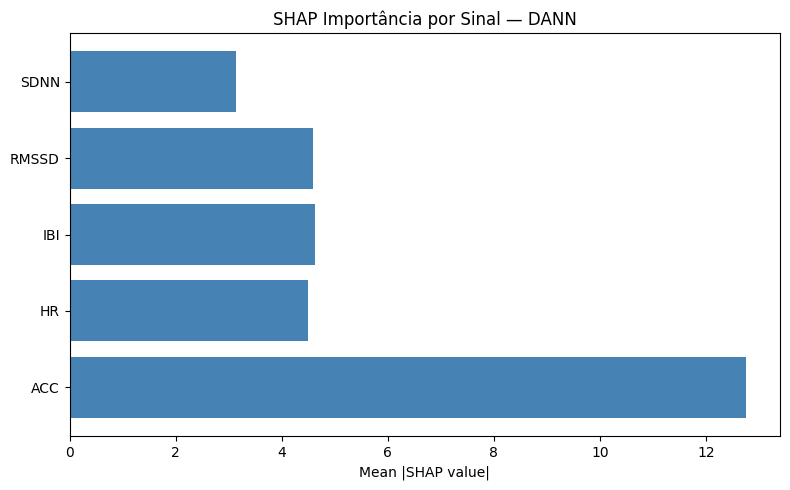


Waterfall — STRESS (DANN)


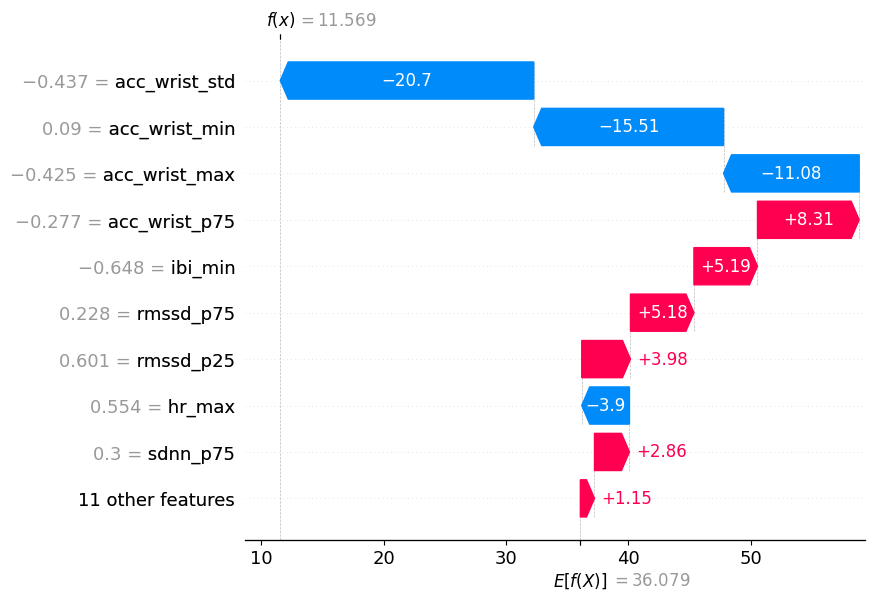


Waterfall — BASELINE (DANN)


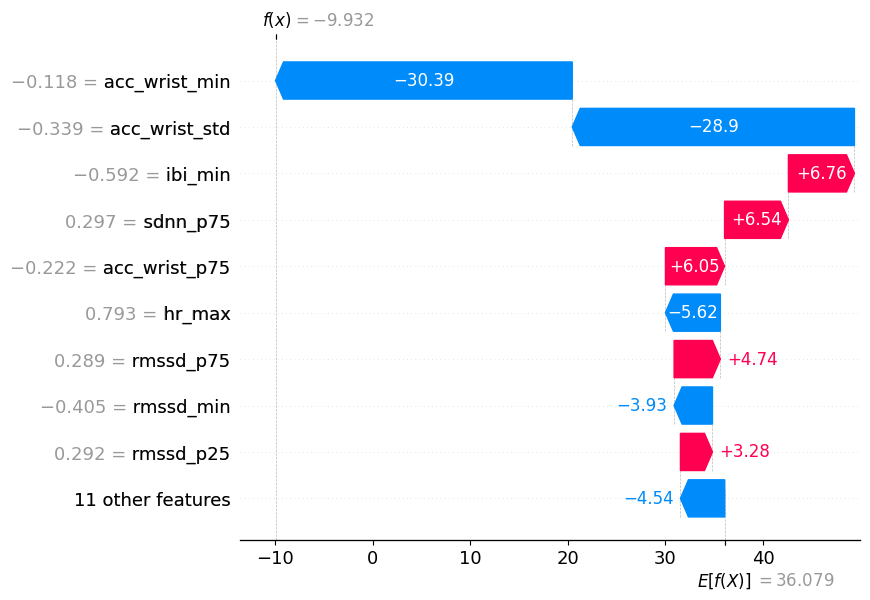


Force plot — STRESS (DANN)


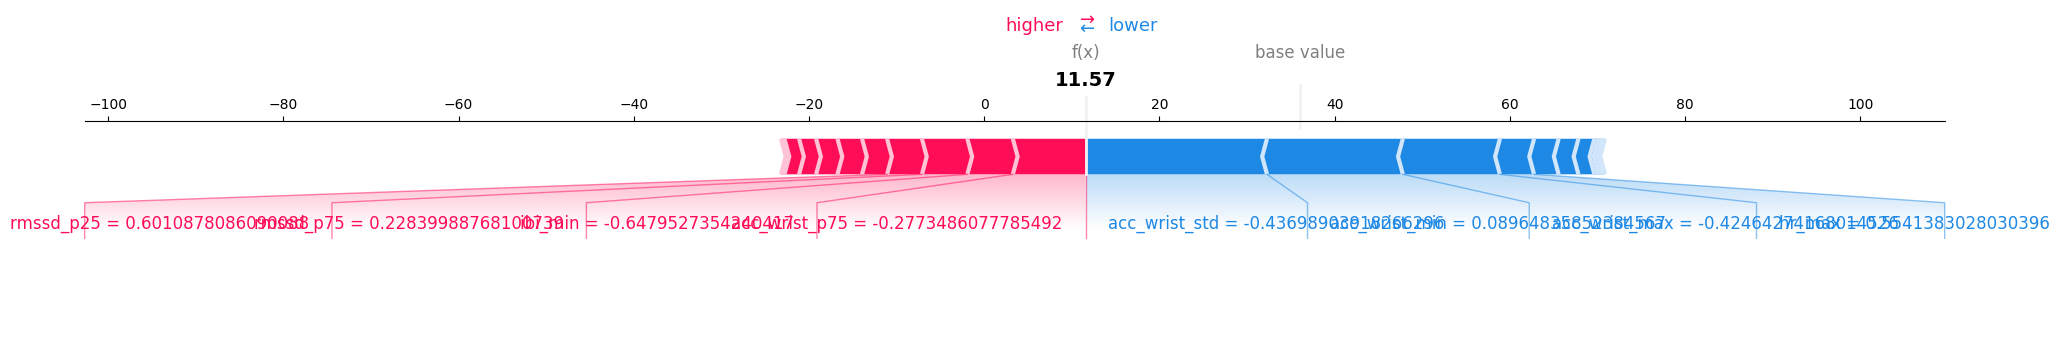


Force plot — BASELINE (DANN)


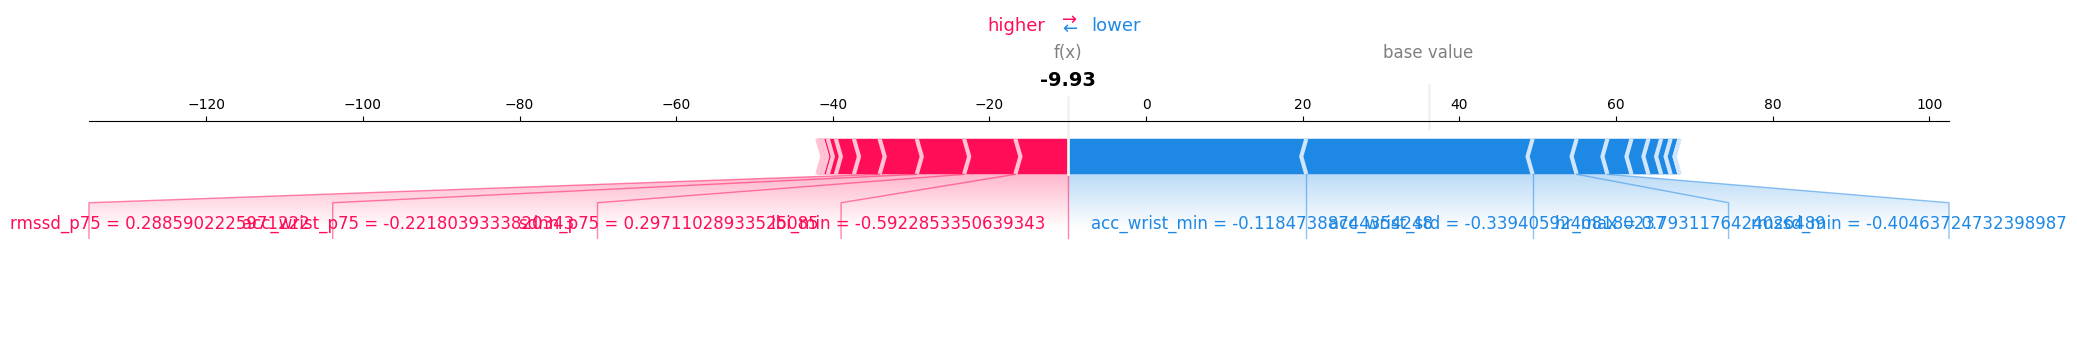


Dependence plot — acc_wrist_min (DANN)


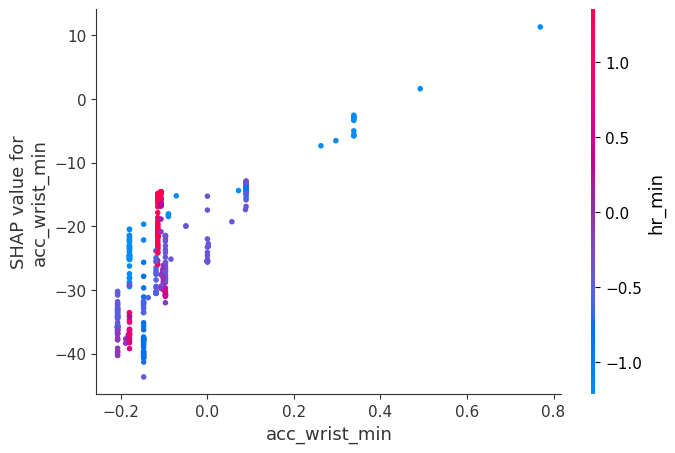


Dependence plot — acc_wrist_std (DANN)


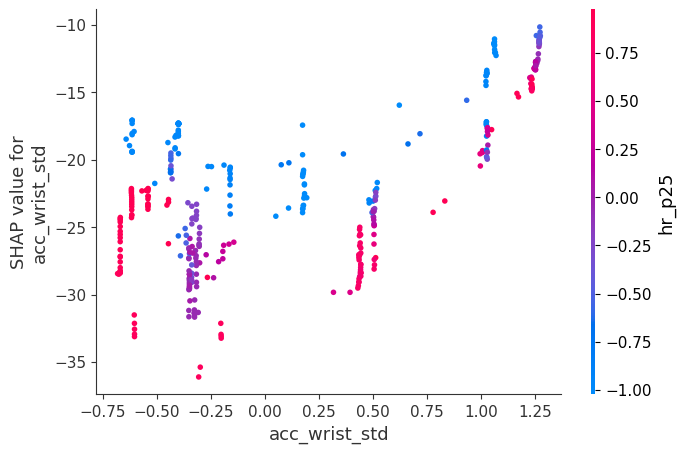


Dependence plot — ibi_min (DANN)


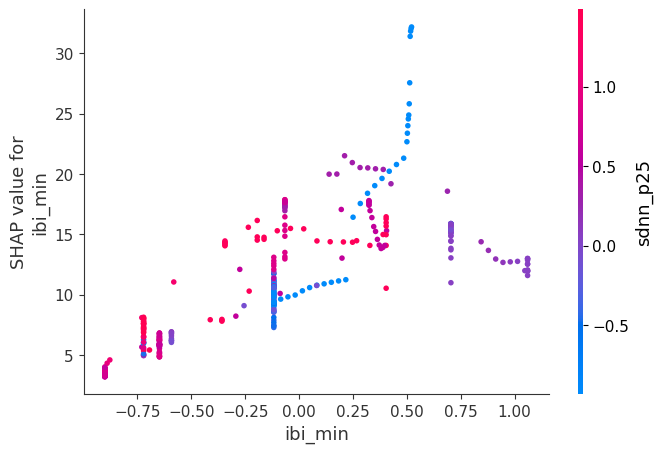

In [15]:
# ── SHAP — DANN (DeepExplainer) ──────────────────────────────────
np.random.seed(42)

bg_0d   = np.where(y.values == 0)[0][:100]
bg_1d   = np.where(y.values == 1)[0][:100]
ts_0d   = np.where(y.values == 0)[0][100:300]
ts_1d   = np.where(y.values == 1)[0][100:300]

X_bg_dann = torch.tensor(X_dann_sel[np.concatenate([bg_0d, bg_1d])])  # (200, 20)
X_ts_dann = torch.tensor(X_dann_sel[np.concatenate([ts_0d, ts_1d])])  # (400, 20)
y_ts_dann = y.values[np.concatenate([ts_0d, ts_1d])]

print("A computar SHAP com DeepExplainer...")
explainer_dann = shap.DeepExplainer(dann_cls, X_bg_dann)
sv_dann_all    = explainer_dann.shap_values(X_ts_dann)

# DeepExplainer devolve (n_samples, n_features, n_classes) — extrai classe 1 (stress)
ev_arr = np.asarray(explainer_dann.expected_value)
if isinstance(sv_dann_all, list):
    sv_dann = sv_dann_all[1]
    ev_dann = float(ev_arr.flat[1])
elif sv_dann_all.ndim == 3:
    sv_dann = sv_dann_all[..., 1]   # (n_samples, 20)
    ev_dann = float(ev_arr.flat[1])
else:
    sv_dann = sv_dann_all
    ev_dann = float(ev_arr.flat[0])

print(f"SHAP shape: {sv_dann.shape}  |  Expected value: {ev_dann:.4f}")

X_ts_np   = X_ts_dann.numpy()
X_ts_df_d = pd.DataFrame(X_ts_np, columns=dann_sel_cols)

# ─── 1. Summary beeswarm ───
shap.summary_plot(sv_dann, X_ts_np, feature_names=dann_sel_cols, show=False)
plt.title('SHAP Summary — DANN')
plt.tight_layout(); plt.show()

# ─── 2. Bar plot ───
shap.summary_plot(sv_dann, X_ts_np, feature_names=dann_sel_cols,
                  plot_type='bar', show=False)
plt.title('SHAP Bar — DANN')
plt.tight_layout(); plt.show()

# ─── 3. Por grupo de sinais ───
gi_dann = signal_group_importance(sv_dann, dann_sel_cols)
plt.figure(figsize=(8, 5))
plt.barh(list(gi_dann.keys()), list(gi_dann.values()), color='steelblue')
plt.title('SHAP Importância por Sinal — DANN')
plt.xlabel('Mean |SHAP value|')
plt.tight_layout(); plt.show()

# ─── 4. Waterfall ───
for label, idx in [('STRESS',   np.where(y_ts_dann == 1)[0][0]),
                   ('BASELINE', np.where(y_ts_dann == 0)[0][0])]:
    print(f"\nWaterfall — {label} (DANN)")
    shap.waterfall_plot(shap.Explanation(
        values        = sv_dann[idx],
        base_values   = ev_dann,
        data          = X_ts_np[idx],
        feature_names = dann_sel_cols
    ))

# ─── 5. Force plots ───
for label, idx in [('STRESS',   np.where(y_ts_dann == 1)[0][0]),
                   ('BASELINE', np.where(y_ts_dann == 0)[0][0])]:
    print(f"\nForce plot — {label} (DANN)")
    shap.force_plot(ev_dann, sv_dann[idx], X_ts_df_d.iloc[idx],
                    matplotlib=True, figsize=(24, 3))
    plt.show()

# ─── 6. Top-3 dependence plots ───
top3_dann = np.argsort(np.abs(sv_dann).mean(axis=0))[::-1][:3]
for i in top3_dann:
    feat = dann_sel_cols[i]
    print(f"\nDependence plot — {feat} (DANN)")
    shap.dependence_plot(feat, sv_dann, X_ts_df_d, show=True)
